# PTB-XL Descriptive Analysis

This notebook provides a brief inspection of the processed demographic predictors, diagnostic outcomes,
class overlap, and an example 12-lead ECG. Run cells from top to bottom after
completing the repository's downloading and preprocessing steps.

## 1. Load and inspect the processed data

The five CSV/ID tables are small. `mmap_mode="r"` opens the large waveform array
without reading all its values into memory. Recording row order links all files.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "configs/preprocessing.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from within the BIOS784 repository.")
DATA = ROOT / "data/processed"
if not (DATA / "COMPLETE.json").is_file():
    raise FileNotFoundError("Complete the preprocessing pipeline before running this notebook.")

predictors = pd.read_csv(DATA / "predictors.csv")
labels = pd.read_csv(DATA / "labels.csv")
splits = pd.read_csv(DATA / "splits.csv")
recording_ids = np.load(DATA / "recording_ids.npy", allow_pickle=False)
schema = json.loads((DATA / "dataset.json").read_text())
X = np.load(DATA / "waveforms.npy", mmap_mode="r", allow_pickle=False)
CLASSES = schema["label_order"]
LEADS = schema["leads"]
FS = schema["sampling_frequency"]

In [ ]:
# Check row alignment before linking tables or selecting a waveform.
assert predictors.ecg_id.is_unique and labels.ecg_id.is_unique and splits.ecg_id.is_unique
for table in [predictors, labels, splits]:
    assert np.array_equal(table.ecg_id.to_numpy(), recording_ids)
assert np.array_equal(predictors.patient_id, splits.patient_id)
assert X.shape == tuple(schema["shape"]) == (len(recording_ids), 1000, 12)
assert np.isin(labels[CLASSES].to_numpy(), [0, 1]).all()
assert np.array_equal(labels.has_diagnostic_label, labels[CLASSES].any(axis=1).astype(int))

df = predictors.merge(labels, on="ecg_id", validate="one_to_one").merge(
    splits[["ecg_id", "strat_fold", "partition"]], on="ecg_id", validate="one_to_one"
)
assert df.patient_id.notna().all()

display(pd.Series({
    "ECG recordings": len(df),
    "Unique patients": df.patient_id.nunique(),
    "Patients with multiple recordings": int(df.groupby("patient_id").size().gt(1).sum()),
    "Waveform shape": str(X.shape),
    "Waveform dtype": str(X.dtype),
    "Sampling frequency (Hz)": FS,
    "Duration (seconds)": X.shape[1] / FS,
    "Waveform units": schema["units"],
    "Waveform file size (decimal GB)": round((DATA / "waveforms.npy").stat().st_size / 1e9, 3),
}, name="Dataset overview").to_frame())
display(predictors.head())

,Dataset overview
ECG recordings,21799
Unique patients,18869
Patients with multiple recordings,2111
Waveform shape,"(21799, 1000, 12)"
Waveform dtype,float32
Sampling frequency (Hz),100
Duration (seconds),10.0
Waveform units,mV
Waveform file size (decimal GB),1.046


,ecg_id,patient_id,age,sex,height,weight,age_deidentified
0,1,15709,56.0,1,NaN,63.0,False
1,2,13243,19.0,0,NaN,70.0,False
2,3,20372,37.0,1,NaN,69.0,False
3,4,17014,24.0,0,NaN,82.0,False
4,5,17448,19.0,1,NaN,70.0,False


## 2. Demographic predictors

Age, sex, height, and weight are the source demographic variables. Sex is coded
0 = male and 1 = female; height is in cm and weight in kg. The additional
`age_deidentified` flag identifies source ages above 89 that must not be interpreted
as literal ages. Retain those source values, but omit flagged ages from the age
summary and histogram below. This is a descriptive display choice, not imputation
or a change to the processed data.

In [ ]:
demographic_columns = ["age", "sex", "height", "weight"]
missingness = pd.DataFrame({
    "observed_recordings": predictors[demographic_columns].notna().sum(),
    "missing_recordings": predictors[demographic_columns].isna().sum(),
    "missing_percent": predictors[demographic_columns].isna().mean().mul(100),
})
display(missingness.round(2))

age_flag = predictors.age_deidentified.fillna(False).astype(bool)
print(f"Deidentified-age recordings (not missing): {age_flag.sum():,}")
print(f"Patients with at least one flagged age: {predictors.loc[age_flag, 'patient_id'].nunique():,}")
numeric_demographics = predictors[["age", "height", "weight"]].copy()
numeric_demographics["age"] = numeric_demographics.age.mask(age_flag)
display(numeric_demographics.describe().T.round(2))

sex_summary = (
    predictors.sex.map({0: "Male", 1: "Female"}).fillna("Missing")
    .value_counts().rename_axis("sex").to_frame("recordings")
)
sex_summary["percent_of_recordings"] = sex_summary.recordings / len(df) * 100
display(sex_summary.round(2))

,observed_recordings,missing_recordings,missing_percent
age,21799,0,0.00
sex,21799,0,0.00
height,6974,14825,68.01
weight,9421,12378,56.78


Deidentified-age recordings (not missing): 293
Patients with at least one flagged age: 262


,count,mean,std,min,25%,50%,75%,max
age,21506.0,59.54,16.76,2.0,50.0,61.0,72.0,89.0
height,6974.0,166.70,10.87,6.0,160.0,166.0,174.0,209.0
weight,9421.0,71.00,15.88,5.0,60.0,70.0,80.0,250.0


,recordings,percent_of_recordings
sex,,
Male,11354,52.08
Female,10445,47.92


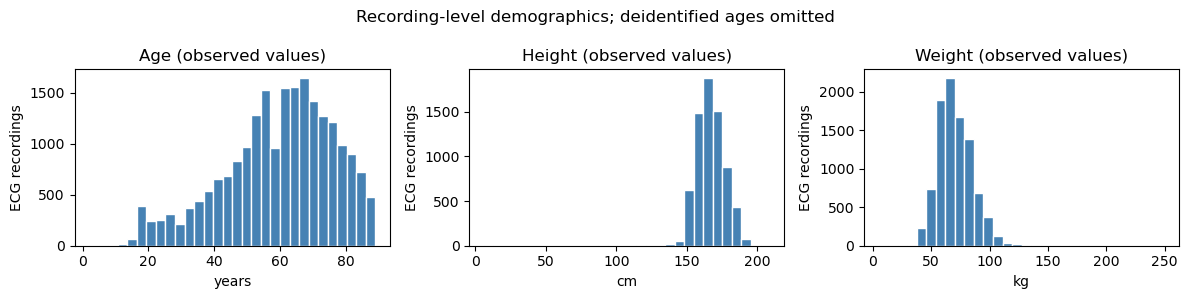

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, column, unit in zip(axes, ["age", "height", "weight"], ["years", "cm", "kg"]):
    ax.hist(numeric_demographics[column].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set(title=f"{column.title()} (observed values)", xlabel=unit, ylabel="ECG recordings")
fig.suptitle("Recording-level demographics; deidentified ages omitted")
fig.tight_layout()
plt.show()

## 3. Diagnostic outcome distribution

Labels are multilabel annotations: NORM = normal ECG, MI = myocardial infarction,
STTC = ST/T changes, CD = conduction disturbance, HYP = hypertrophy. Percentages
use **all recordings** or **all unique patients** as specified, including records
without any of these labels. A patient's class is positive if any of their ECGs
has that label; this does not imply all diagnoses occurred at the same time.
Class percentages can sum to more than 100%.

,positive_recordings,percent_of_all_recordings,patients_with_any_positive_ECG,percent_of_all_patients
NORM,9514,43.64,8896,47.15
MI,5469,25.09,4670,24.75
STTC,5235,24.01,4577,24.26
CD,4898,22.47,4295,22.76
HYP,2649,12.15,2384,12.63


,recordings
positive_labels,
0,411
1,16244
2,4068
3,919
4,157


Multilabel ECGs: 5,144
ECGs without a diagnostic superclass: 411
Diagnostic-eligible ECGs: 21,388
Patients with no positive superclass across all their ECGs: 252


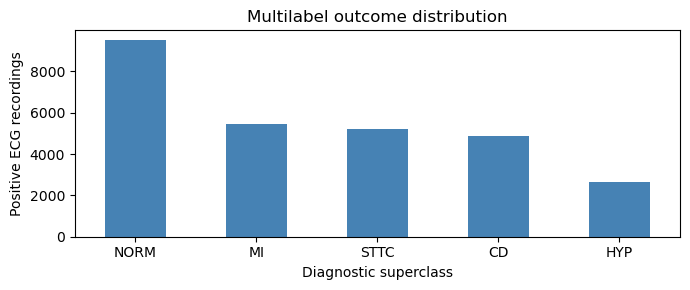

In [ ]:
# int64 prevents overflow when counting co-occurrence with matrix multiplication.
y = df[CLASSES].astype("int64")
patient_labels = df.groupby("patient_id")[CLASSES].max().astype("int64")
outcome_summary = pd.DataFrame({
    "positive_recordings": y.sum(),
    "percent_of_all_recordings": y.mean().mul(100),
    "patients_with_any_positive_ECG": patient_labels.sum(),
    "percent_of_all_patients": patient_labels.mean().mul(100),
})
display(outcome_summary.round(2))

labels_per_recording = y.sum(axis=1)
label_count_summary = labels_per_recording.value_counts().sort_index().rename_axis("positive_labels")
display(label_count_summary.to_frame("recordings"))
print(f"Multilabel ECGs: {labels_per_recording.gt(1).sum():,}")
print(f"ECGs without a diagnostic superclass: {labels_per_recording.eq(0).sum():,}")
print(f"Diagnostic-eligible ECGs: {df.has_diagnostic_label.sum():,}")
print(f"Patients with no positive superclass across all their ECGs: {patient_labels.sum(axis=1).eq(0).sum():,}")

ax = outcome_summary.positive_recordings.plot.bar(color="steelblue", figsize=(7, 3), rot=0)
ax.set(xlabel="Diagnostic superclass", ylabel="Positive ECG recordings", title="Multilabel outcome distribution")
plt.tight_layout()
plt.show()

## 4. Patient and class overlap

The first matrix counts ECGs with **both labels on the same recording**. The second
counts unique patients with **both labels anywhere in their available recordings**.
Diagonals are the total positive count for each class, not overlap between different
classes. Patient-level overlap may include diagnoses from different recordings;
it is annotation overlap rather than confirmed simultaneous disease.

,NORM,MI,STTC,CD,HYP
same-ECG overlap,,,,,
NORM,9514,1,33,415,5
MI,1,5469,1339,1794,818
STTC,33,1339,5235,1066,1509
CD,415,1794,1066,4898,787
HYP,5,818,1509,787,2649


,NORM,MI,STTC,CD,HYP
patient-level overlap,,,,,
NORM,8896,130,230,495,54
MI,130,4670,1288,1634,780
STTC,230,1288,4577,1029,1355
CD,495,1634,1029,4295,760
HYP,54,780,1355,760,2384


,class_pair,ECGs_with_both_labels,patients_with_both_labels_any_recording,percent_of_patients_with_either_label
0,MI + CD,1794,1634,22.29
1,STTC + HYP,1509,1355,24.17
2,MI + STTC,1339,1288,16.18
3,STTC + CD,1066,1029,13.12
4,MI + HYP,818,780,12.43
5,CD + HYP,787,760,12.84
6,NORM + CD,415,495,3.90
7,NORM + STTC,33,230,1.74
8,NORM + MI,1,130,0.97
9,NORM + HYP,5,54,0.48


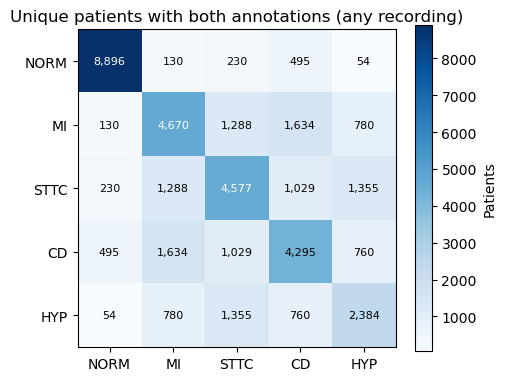

In [ ]:
ecg_overlap = y.T @ y
patient_overlap = patient_labels.T @ patient_labels
display(ecg_overlap.rename_axis("same-ECG overlap"))
display(patient_overlap.rename_axis("patient-level overlap"))

pairs = []
for i, a in enumerate(CLASSES):
    for b in CLASSES[i + 1:]:
        union = int((patient_labels[a].eq(1) | patient_labels[b].eq(1)).sum())
        both = int(patient_overlap.loc[a, b])
        pairs.append({
            "class_pair": f"{a} + {b}",
            "ECGs_with_both_labels": int(ecg_overlap.loc[a, b]),
            "patients_with_both_labels_any_recording": both,
            "percent_of_patients_with_either_label": 100 * both / union if union else np.nan,
        })
pair_summary = pd.DataFrame(pairs).sort_values(
    "patients_with_both_labels_any_recording", ascending=False
)
display(pair_summary.round(2).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(patient_overlap.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(CLASSES)), labels=CLASSES)
ax.set_yticks(range(len(CLASSES)), labels=CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        count = int(patient_overlap.iloc[i, j])
        color = "white" if count > patient_overlap.to_numpy().max() / 2 else "black"
        ax.text(j, i, f"{count:,}", ha="center", va="center", color=color, fontsize=8)
ax.set_title("Unique patients with both annotations (any recording)")
fig.colorbar(image, ax=ax, label="Patients")
fig.tight_layout()
plt.show()

## 5. Official partitions and patient separation

Training uses folds 1–8, validation fold 9, and test fold 10. Overlap of diagnostic
classes within a patient is expected in a multilabel dataset; overlap of patient
IDs across these partitions should be zero.

In [ ]:
partitions = ["train", "validation", "test"]
partition_summary = df.groupby("partition").agg(
    recordings=("ecg_id", "size"), patients=("patient_id", "nunique"),
    diagnostic_eligible=("has_diagnostic_label", "sum"),
).reindex(partitions)
display(partition_summary)

patient_sets = {p: set(df.loc[df.partition.eq(p), "patient_id"]) for p in partitions}
split_overlap = pd.DataFrame(
    [[len(patient_sets[a] & patient_sets[b]) for b in partitions] for a in partitions],
    index=partitions, columns=partitions,
)
display(split_overlap.rename_axis("patient-ID overlap; diagonal = partition total"))
assert df.groupby("patient_id").partition.nunique().max() == 1
expected_partition = np.where(df.strat_fold.le(8), "train", np.where(df.strat_fold.eq(9), "validation", "test"))
assert np.array_equal(df.partition, expected_partition)
assert df.strat_fold.between(1, 10).all()

partition_label_counts = df.groupby("partition")[CLASSES].sum().reindex(partitions)
partition_label_percent = partition_label_counts.div(partition_summary.recordings, axis=0).mul(100)
print("Percent positive within each partition (all recordings):")
display(partition_label_percent.round(2))

,recordings,patients,diagnostic_eligible
partition,,,
train,17418,15023,17084
validation,2183,1942,2146
test,2198,1904,2158


,train,validation,test
patient-ID overlap; diagonal = partition total,,,
train,15023,0,0
validation,0,1942,0
test,0,0,1904


Percent positive within each partition (all recordings):


,NORM,MI,STTC,CD,HYP
partition,,,,,
train,43.61,25.14,24.03,22.43,12.17
validation,43.75,24.74,24.19,22.68,12.28
test,43.81,25.02,23.70,22.57,11.92


## 6. Inspect one example ECG and its 12 leads

`X[recording_row, time_index, lead_index]` is a voltage amplitude in mV.
At 100 Hz, sample 250 is 2.50 seconds after recording start; indices start at zero.
Positive and negative amplitudes reflect the voltage difference measured by that
lead. Choose a **row index**, not an ECG ID, below; `recording_ids` provides the link.
The default is the first training ECG, selected deterministically without inspecting
its diagnosis. Only this recording (about 48 KB of float32 values) is read.

The example summaries describe amplitudes; they are not clinical interval measures
such as heart rate, PR, QRS, or QT, and are not representative of the whole dataset.

In [ ]:
example_row = int(np.flatnonzero(df.partition.eq("train").to_numpy())[0])
example_ecg = np.array(X[example_row], copy=True)
example_id = int(recording_ids[example_row])
assert df.iloc[example_row].ecg_id == example_id
assert np.isfinite(example_ecg).all()

print(f"ECG ID: {example_id}; partition: {df.iloc[example_row].partition}")
print(f"Shape: {example_ecg.shape}; dtype: {example_ecg.dtype}; units: {schema['units']}")
print(f"Duration: {len(example_ecg) / FS:g} s; sampling interval: {1 / FS:g} s")
print("Positive superclass annotations:", [c for c in CLASSES if df.iloc[example_row][c] == 1])
print(f"Lead {LEADS[0]} at 2.50 s: {example_ecg[250, 0]:.3f} mV")

lead_summary = pd.DataFrame({
    "mean_mV": example_ecg.mean(axis=0),
    "SD_mV": example_ecg.std(axis=0, ddof=1),
    "min_mV": example_ecg.min(axis=0),
    "max_mV": example_ecg.max(axis=0),
    "peak_to_peak_mV": np.ptp(example_ecg, axis=0),
}, index=pd.Index(LEADS, name="lead"))
display(lead_summary.round(3))

ECG ID: 1; partition: train
Shape: (1000, 12); dtype: float32; units: mV
Duration: 10 s; sampling interval: 0.01 s
Positive superclass annotations: ['NORM']
Lead I at 2.50 s: -0.069 mV


,mean_mV,SD_mV,min_mV,max_mV,peak_to_peak_mV
lead,,,,,
I,0.002,0.109,-0.195,0.706,0.901
II,0.001,0.083,-0.140,0.435,0.575
III,-0.001,0.059,-0.312,0.130,0.442
AVR,-0.001,0.092,-0.559,0.138,0.697
AVL,0.001,0.077,-0.155,0.500,0.655
AVF,0.000,0.047,-0.100,0.172,0.272
V1,-0.002,0.113,-0.704,0.142,0.846
V2,0.007,0.214,-1.377,0.410,1.787
V3,-0.002,0.118,-0.618,0.620,1.238


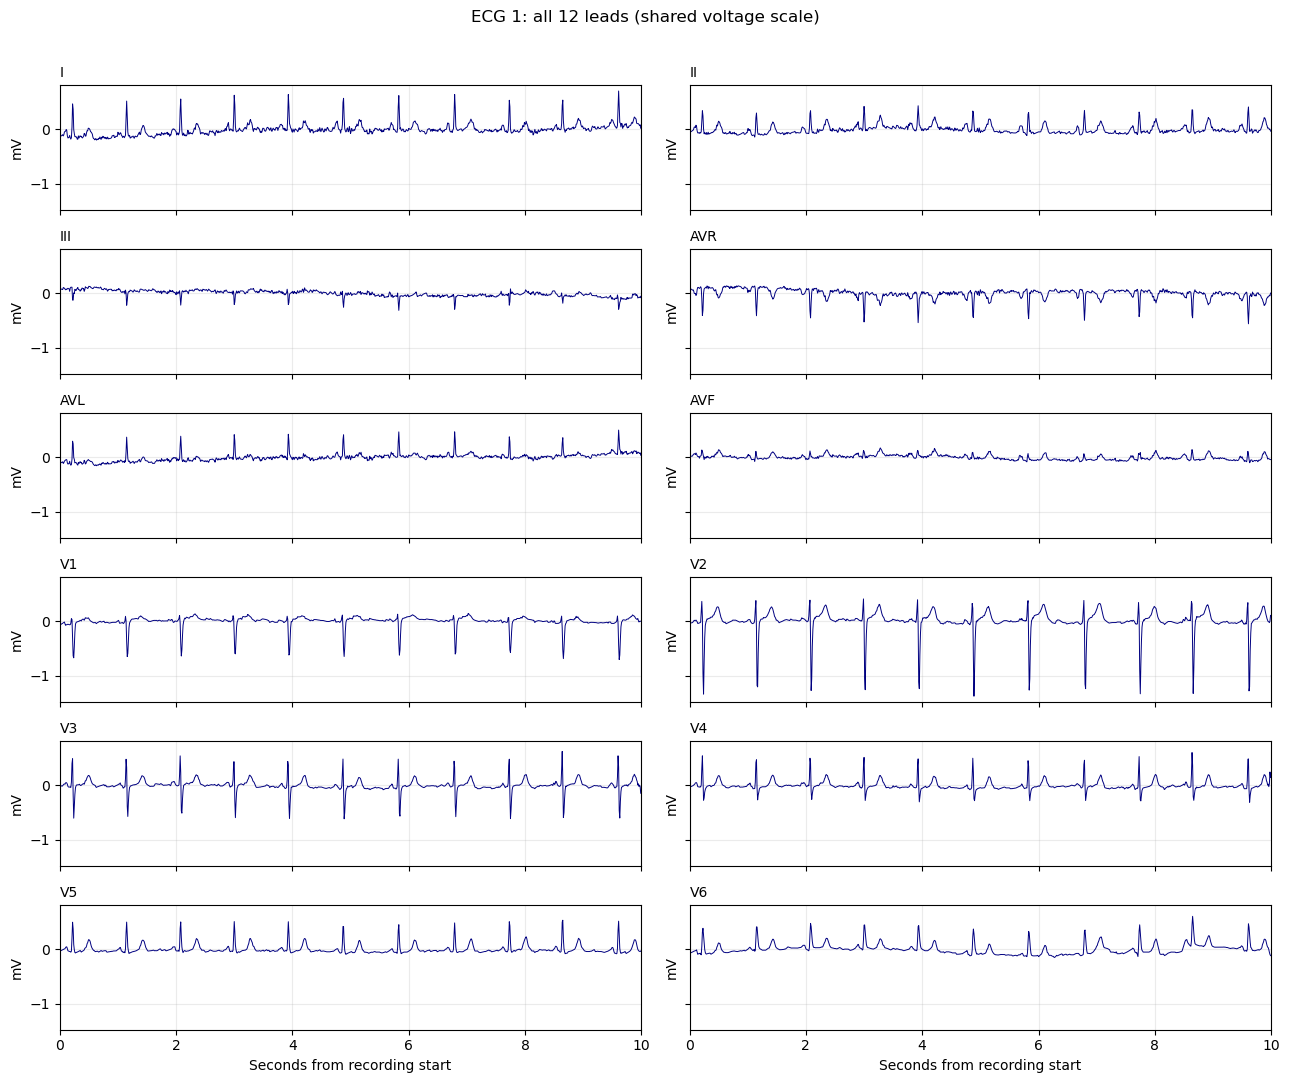

In [ ]:
time_seconds = np.arange(example_ecg.shape[0]) / FS
fig, axes = plt.subplots(6, 2, figsize=(13, 11), sharex=True, sharey=True)
for lead_index, ax in enumerate(axes.flat):
    ax.plot(time_seconds, example_ecg[:, lead_index], linewidth=0.7, color="navy")
    ax.set_title(LEADS[lead_index], loc="left", fontsize=10)
    ax.set_ylabel("mV")
    ax.grid(alpha=0.25)
    ax.set_xlim(0, len(example_ecg) / FS)
for ax in axes[-1]:
    ax.set_xlabel("Seconds from recording start")
fig.suptitle(f"ECG {example_id}: all 12 leads (shared voltage scale)")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 7. Interpretation notes

- Missing demographic measurements remain missing; flagged ages are excluded only
  from descriptive age displays. Source predictors are unchanged.
- ECG-level summaries weight patients with repeated ECGs more heavily. Patient-level
  diagnostic summaries collapse each class with an **any-positive-recording** rule.
- All-zero diagnostic rows are retained and counted separately. A missing superclass
  annotation is not proof of absence of disease; use the eligibility flag consistently
  when defining a later modeling cohort.
- NORM overlap with other classes can arise in annotation combinations or across
  repeat recordings. These tables describe the data and do not adjudicate diagnoses.
- The waveform summaries and plots show **one example**, not global ECG statistics.
  Memory mapping is efficient, but `X[:]` calculations or selecting every row with
  advanced indexing can still read or copy the full array.
- These are descriptive results, including held-out-partition summaries; they should
  not be used to fit normalization, imputation, or other modeling transformations.

Definitions and preprocessing provenance are in the repository README,
`data/processed/dataset.json`, and `reports/preprocessing_qc/data_dictionary.csv`.